# K-Means Seller Segmentation
**Tzy — bước 4.** Dùng ma trận từ notebook đặc trưng v2; seed 42, n_init 30.
Đây là mô hình K-Means ứng viên để Phu0c so sánh GMM/DBSCAN, chưa chốt mô hình phân khúc cuối cùng.


In [1]:
"""Tzy step 4: reproducible K-Means selection, stability and cohort sensitivity."""
from __future__ import annotations
import argparse
import json
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from threadpoolctl import threadpool_limits


def evaluate(matrix, ks=range(2,11)):
    x=matrix.to_numpy(dtype=float)
    if not np.isfinite(x).all() or not matrix.index.is_unique:
        raise ValueError('Invalid clustering matrix')
    rows=[];models={}
    with threadpool_limits(limits=2):
        for k in ks:
            model=KMeans(n_clusters=k,random_state=42,n_init=30,algorithm='lloyd').fit(x)
            sizes=np.bincount(model.labels_,minlength=k)
            rows.append({'k':k,'inertia':model.inertia_,
                         'silhouette':silhouette_score(x,model.labels_),
                         'davies_bouldin':davies_bouldin_score(x,model.labels_),
                         'calinski_harabasz':calinski_harabasz_score(x,model.labels_),
                         'min_cluster_size':int(sizes.min()),'max_cluster_size':int(sizes.max()),
                         'min_cluster_share':float(sizes.min()/len(x))})
            models[k]=model
    return pd.DataFrame(rows),models


def run_kmeans(inputs,output):
    inputs,output=Path(inputs),Path(output);output.mkdir(parents=True,exist_ok=True)
    matrix=pd.read_csv(inputs/'seller_model_input.csv').set_index('seller_id')
    all_matrix=pd.read_csv(inputs/'seller_model_input_all.csv').set_index('seller_id')
    features=pd.read_csv(inputs/'seller_features.csv').set_index('seller_id')
    metrics,models=evaluate(matrix)
    # A tiny outlier cluster can inflate silhouette without useful seller segments.
    viable=metrics.loc[metrics.min_cluster_share.ge(.02)]
    if viable.empty:
        raise ValueError('No k with minimum cluster size >= 2%; inspect candidates rather than silently accepting')
    k=int(viable.sort_values(['silhouette','k'],ascending=[False,True]).iloc[0].k)
    model=models[k];labels=pd.Series(model.labels_,index=matrix.index,name='kmeans_cluster')
    with threadpool_limits(limits=2):
        stability=[]
        for seed in [0,1,7,21,42,84,123,256,512,1024]:
            other=KMeans(n_clusters=k,random_state=seed,n_init=30).fit(matrix.to_numpy())
            stability.append({'seed':seed,'ari_to_seed42':adjusted_rand_score(labels,other.labels_),'inertia':other.inertia_})
        sensitivity_metrics,sensitivity_models=evaluate(all_matrix)
    all_k_model=sensitivity_models[k]
    all_labels=pd.Series(all_k_model.labels_,index=all_matrix.index)
    shared=matrix.index.intersection(all_matrix.index)
    sensitivity_ari=adjusted_rand_score(labels.loc[shared],all_labels.loc[shared])
    # Separate cohort is fit/scaled independently; comparison includes that policy change.
    assignments=features.join(labels)
    assignments['segment_status']=np.where(assignments.kmeans_cluster.notna(),'KMeans candidate',
                                         'Insufficient delivered orders')
    assignments['seller_segment']=assignments.kmeans_cluster.map(lambda x:f'KMeans C{int(x)}' if pd.notna(x) else 'Insufficient orders')
    numeric=features.select_dtypes('number').columns
    grouped=assignments.dropna(subset=['kmeans_cluster']).groupby('kmeans_cluster')
    medians=grouped[list(numeric)].median()
    means=grouped[list(numeric)].mean()
    summary=grouped.agg(sellers=('order_count','size'),total_sales=('total_sales','sum'),
                        orders_median=('order_count','median'),aov_median=('avg_order_value','median'),
                        review_mean=('review_score_mean','mean'),late_rate_mean=('late_delivery_rate','mean'),
                        distance_median=('avg_ship_distance_km','median'))
    summary['seller_share']=summary.sellers/len(matrix)
    summary['sales_share']=summary.total_sales/summary.total_sales.sum()
    with threadpool_limits(limits=2):
        pca=PCA(n_components=2,random_state=42).fit(matrix)
        coords=pd.DataFrame(pca.transform(matrix),columns=['PC1','PC2'],index=matrix.index)
    coords['kmeans_cluster']=labels
    for name,frame,index in [('kmeans_metrics',metrics,False),('kmeans_stability',pd.DataFrame(stability),False),
                             ('cohort_sensitivity_metrics',sensitivity_metrics,False),('seller_assignments',assignments,True),
                             ('cluster_summary',summary,True),('cluster_medians',medians,True),('cluster_means',means,True),
                             ('pca_coordinates',coords,True)]:
        frame.to_csv(output/f'{name}.csv',index=index,float_format='%.12g')
    # Dimension handoff also includes sellers without delivered sales.
    dim=assignments[['seller_segment','seller_region','segment_status']].reset_index()
    excluded=pd.read_csv(inputs/'excluded_sellers.csv')
    absent=excluded.loc[~excluded.seller_id.isin(dim.seller_id)].copy()

    absent['seller_region']=absent.seller_state.map(REGIONS).fillna('Unknown')
    absent['seller_segment']='No eligible delivered sales';absent['segment_status']='Outside cohort'
    dim=pd.concat([dim,absent[dim.columns]],ignore_index=True).sort_values('seller_id')
    assert dim.seller_id.is_unique
    dim.to_csv(output/'seller_segment_dimension.csv',index=False)
    details={'selected_k':k,'selection_rule':'Maximum full-cohort silhouette over k=2..10 with minimum cluster share >= 2%; inspect elbow alongside',
             'random_state':42,'n_init':30,'model_shape':list(matrix.shape),'feature_order':matrix.columns.tolist(),
             'matrix_sha256':hashlib.sha256((inputs/'seller_model_input.csv').read_bytes()).hexdigest(),
             'selected_metrics':metrics.loc[metrics.k.eq(k)].iloc[0].to_dict(),
             'stability_ari_min':float(pd.DataFrame(stability).ari_to_seed42.min()),
             'stability_ari_mean':float(pd.DataFrame(stability).ari_to_seed42.mean()),
             'all_seller_same_k_ari_on_shared_sellers':float(sensitivity_ari),
             'all_seller_best_silhouette_k':int(sensitivity_metrics.sort_values('silhouette',ascending=False).iloc[0].k),
             'pca_explained_variance_ratio':pca.explained_variance_ratio_.tolist(),
             'status':'KMeans candidate; final comparison with GMM and DBSCAN belongs to Phu0c',
             'limitations':['Historical descriptive clustering, not out-of-sample validation',
                            'Geography uses zip centroids, not actual shipping route',
                            'Review and delivery shared by all sellers of an order',
                            'Review answer timestamp records customer survey response, not seller response',
                            'Cancellation denominator covers only orders with seller-attributable items']}
    (output/'kmeans_selection.json').write_text(json.dumps(details,indent=2,ensure_ascii=False,allow_nan=False),encoding='utf-8')
    import joblib
    joblib.dump(model,output/'kmeans_model.joblib')
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    fig,axes=plt.subplots(1,2,figsize=(12,4),layout='constrained')
    for ax,y,title in [(axes[0],'inertia','Elbow'),(axes[1],'silhouette','Silhouette (all observations)')]:
        ax.plot(metrics.k,metrics[y],'o-');ax.axvline(k,color='firebrick',ls='--',label=f'Selected k={k}')
        ax.set(title=title,xlabel='k',ylabel=y);ax.set_xticks(metrics.k);ax.legend()
    fig.savefig(output/'elbow_silhouette.png',dpi=180);plt.close(fig)
    fig,ax=plt.subplots(figsize=(9,6),layout='constrained')
    for cluster in range(k):
        part=coords.loc[coords.kmeans_cluster.eq(cluster)]
        ax.scatter(part.PC1,part.PC2,s=13,alpha=.5,label=f'C{cluster} (n={len(part)})')
    ax.set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.1%})',ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.1%})',
           title='K-Means in PCA view (fit uses all selected features)');ax.legend()
    fig.savefig(output/'pca_kmeans.png',dpi=180);plt.close(fig)
    centers=pd.DataFrame(model.cluster_centers_,columns=matrix.columns)
    centers.to_csv(output/'cluster_centers_scaled.csv',index_label='kmeans_cluster')
    fig,ax=plt.subplots(figsize=(12,4),layout='constrained')
    im=ax.imshow(centers,aspect='auto',cmap='RdBu_r',vmin=-2,vmax=2)
    ax.set_xticks(range(len(matrix.columns)),matrix.columns,rotation=60,ha='right',fontsize=8)
    ax.set_yticks(range(k),[f'C{i}' for i in range(k)]);fig.colorbar(im,ax=ax,label='z-score; color limit +/-2',extend='both')
    fig.savefig(output/'cluster_centroids.png',dpi=180);plt.close(fig)
    return details,metrics,summary



REGIONS = {**dict.fromkeys(['SP','RJ','MG','ES'], 'Sudeste'),
           **dict.fromkeys(['PR','SC','RS'], 'Sul'),
           **dict.fromkeys(['BA','SE','AL','PE','PB','RN','CE','PI','MA'], 'Nordeste'),
           **dict.fromkeys(['AM','RR','AP','PA','TO','RO','AC'], 'Norte'),
           **dict.fromkeys(['MT','MS','GO','DF'], 'Centro-Oeste')}


In [2]:
import os
ROOT=Path.cwd().parent if Path.cwd().name=='notebooks' else Path.cwd()
INPUTS=Path(os.environ.get('OLIST_FEATURE_OUTPUT',str(ROOT/'artifacts/seller_segmentation_v2')))
OUTPUT=Path(os.environ.get('OLIST_KMEANS_OUTPUT',str(ROOT/'artifacts/seller_kmeans')))
details,metrics,summary=run_kmeans(INPUTS,OUTPUT)
display(metrics)
print('k được chọn:',details['selected_k'])
print('Quy tắc:',details['selection_rule'])


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,min_cluster_share
0,2,22195.097031,0.144873,2.187981,321.315316,691,1438,0.324566
1,3,19835.100798,0.132207,2.070278,306.164910,644,803,0.302489
2,4,18233.870814,0.144465,1.980974,284.132840,257,673,0.120714
3,5,16770.914161,0.148018,1.754222,277.899734,55,655,0.025834
4,6,15338.824349,0.154638,1.565287,282.604187,23,656,0.010803
5,7,14460.361646,0.137996,1.599874,271.177734,23,550,0.010803
6,8,13802.579932,0.135449,1.626892,257.841691,23,456,0.010803
7,9,13233.651923,0.133266,1.690087,246.591210,23,387,0.010803
8,10,12854.932761,0.119448,1.714824,232.479797,22,365,0.010333


k được chọn: 5
Quy tắc: Maximum full-cohort silhouette over k=2..10 with minimum cluster share >= 2%; inspect elbow alongside


## Elbow và Silhouette
Quét k=2..10, tính Silhouette trên toàn bộ cohort. Chọn Silhouette cao nhất trong các k có mọi cụm ≥2% cohort; biểu đồ Elbow hỗ trợ kiểm tra, không khẳng định có điểm khuỷu rõ khi dữ liệu không cho thấy.


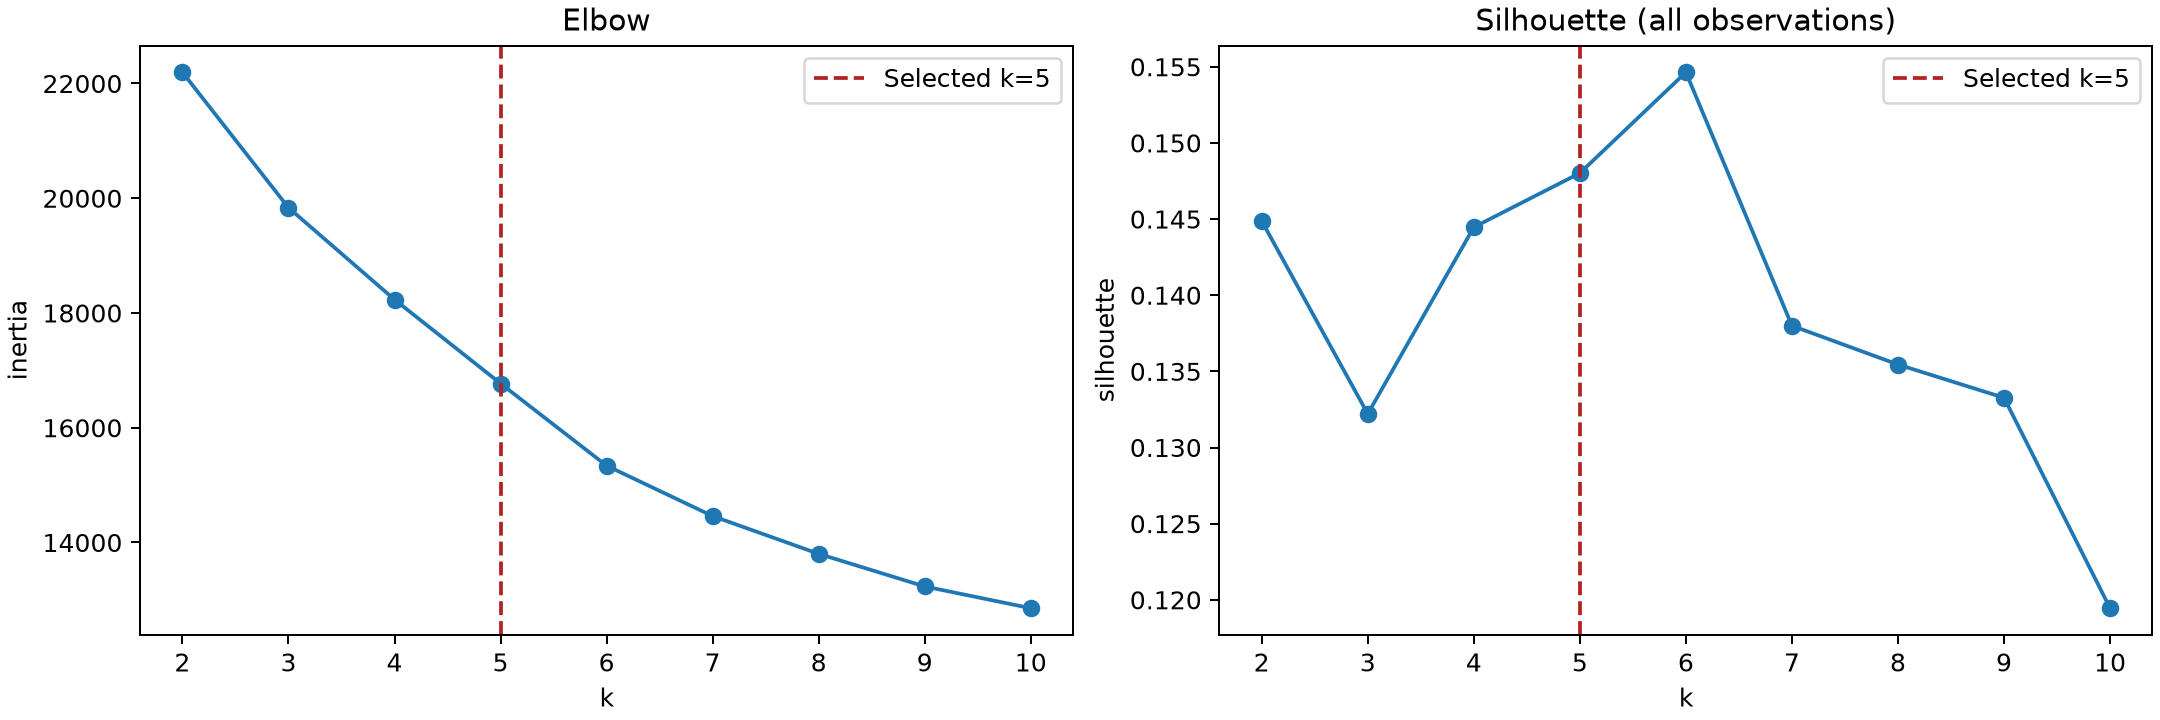

,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,min_cluster_share
0,5.0,16770.914161,0.148018,1.754222,277.899734,55.0,655.0,0.025834


In [3]:
from IPython.display import display,Image
display(Image(filename=str(OUTPUT/'elbow_silhouette.png')))
display(pd.DataFrame([details['selected_metrics']]))


## Độ ổn định và ảnh hưởng của seller ít đơn
Chạy 10 seed và đối chiếu ARI với seed 42. Chạy cùng k trên cohort toàn bộ seller, fit lại scaler, rồi tính ARI trên seller chung. ARI khác nhau phản ánh cả thay đổi cohort lẫn chuẩn hóa.


In [4]:
display(pd.read_csv(OUTPUT/'kmeans_stability.csv'))
display(pd.read_csv(OUTPUT/'cohort_sensitivity_metrics.csv'))
print('ARI chung khi giữ seller ít đơn:',details['all_seller_same_k_ari_on_shared_sellers'])
print('Silhouette thấp nghĩa là cụm còn chồng lấn; ổn định theo seed không chứng minh các phân khúc tách biệt tốt.')


,seed,ari_to_seed42,inertia
0,0,0.998657,16770.895456
1,1,0.997175,16770.947190
2,7,0.998657,16770.895456
3,21,0.997174,16770.925998
4,42,1.000000,16770.914161
5,84,1.000000,16770.914161
6,123,0.998657,16770.895456
7,256,0.998657,16770.895456
8,512,0.997174,16770.967427
9,1024,0.997175,16770.947190


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_size,max_cluster_size,min_cluster_share
0,2,31221.761390,0.142569,2.278336,420.006163,1092,1878,0.367677
1,3,27673.820925,0.145557,2.004397,427.039934,913,1100,0.307407
2,4,25076.295005,0.157134,1.768378,416.488937,103,1135,0.034680
3,5,23054.669388,0.165667,1.557896,404.652755,52,1126,0.017508
4,6,21159.051720,0.171225,1.396148,405.709733,22,1103,0.007407
5,7,19730.118439,0.176468,1.369794,398.215037,24,1066,0.008081
6,8,18623.618608,0.166221,1.508825,386.625198,24,790,0.008081
7,9,17618.596098,0.151910,1.513858,378.589899,24,618,0.008081
8,10,16900.610297,0.154873,1.494604,364.671864,24,593,0.008081


ARI chung khi giữ seller ít đơn: 0.5583731620793341
Silhouette thấp nghĩa là cụm còn chồng lấn; ổn định theo seed không chứng minh các phân khúc tách biệt tốt.


## Profile và bàn giao OLAP
PCA 2D chỉ để xem; K-Means được fit trên toàn bộ đặc trưng đã chọn. Mã C0..Ck là nhãn kỹ thuật, chưa phải tên phân khúc nghiệp vụ cuối cùng.


,sellers,total_sales,orders_median,aov_median,review_mean,late_rate_mean,distance_median,seller_share,sales_share
kmeans_cluster,,,,,,,,,
0.0,55,74700.77,6.0,103.908333,4.094811,0.074995,619.270677,0.025834,0.005765
1.0,647,1550159.73,9.0,111.000000,4.280368,0.032016,620.327625,0.303899,0.119641
2.0,532,745769.94,7.0,93.125000,4.414725,0.024407,444.593981,0.249883,0.057559
3.0,240,693852.68,7.0,160.602149,3.524562,0.250153,666.141656,0.112729,0.053552
4.0,655,9892239.33,62.0,110.804348,4.145623,0.063821,575.353192,0.307656,0.763483


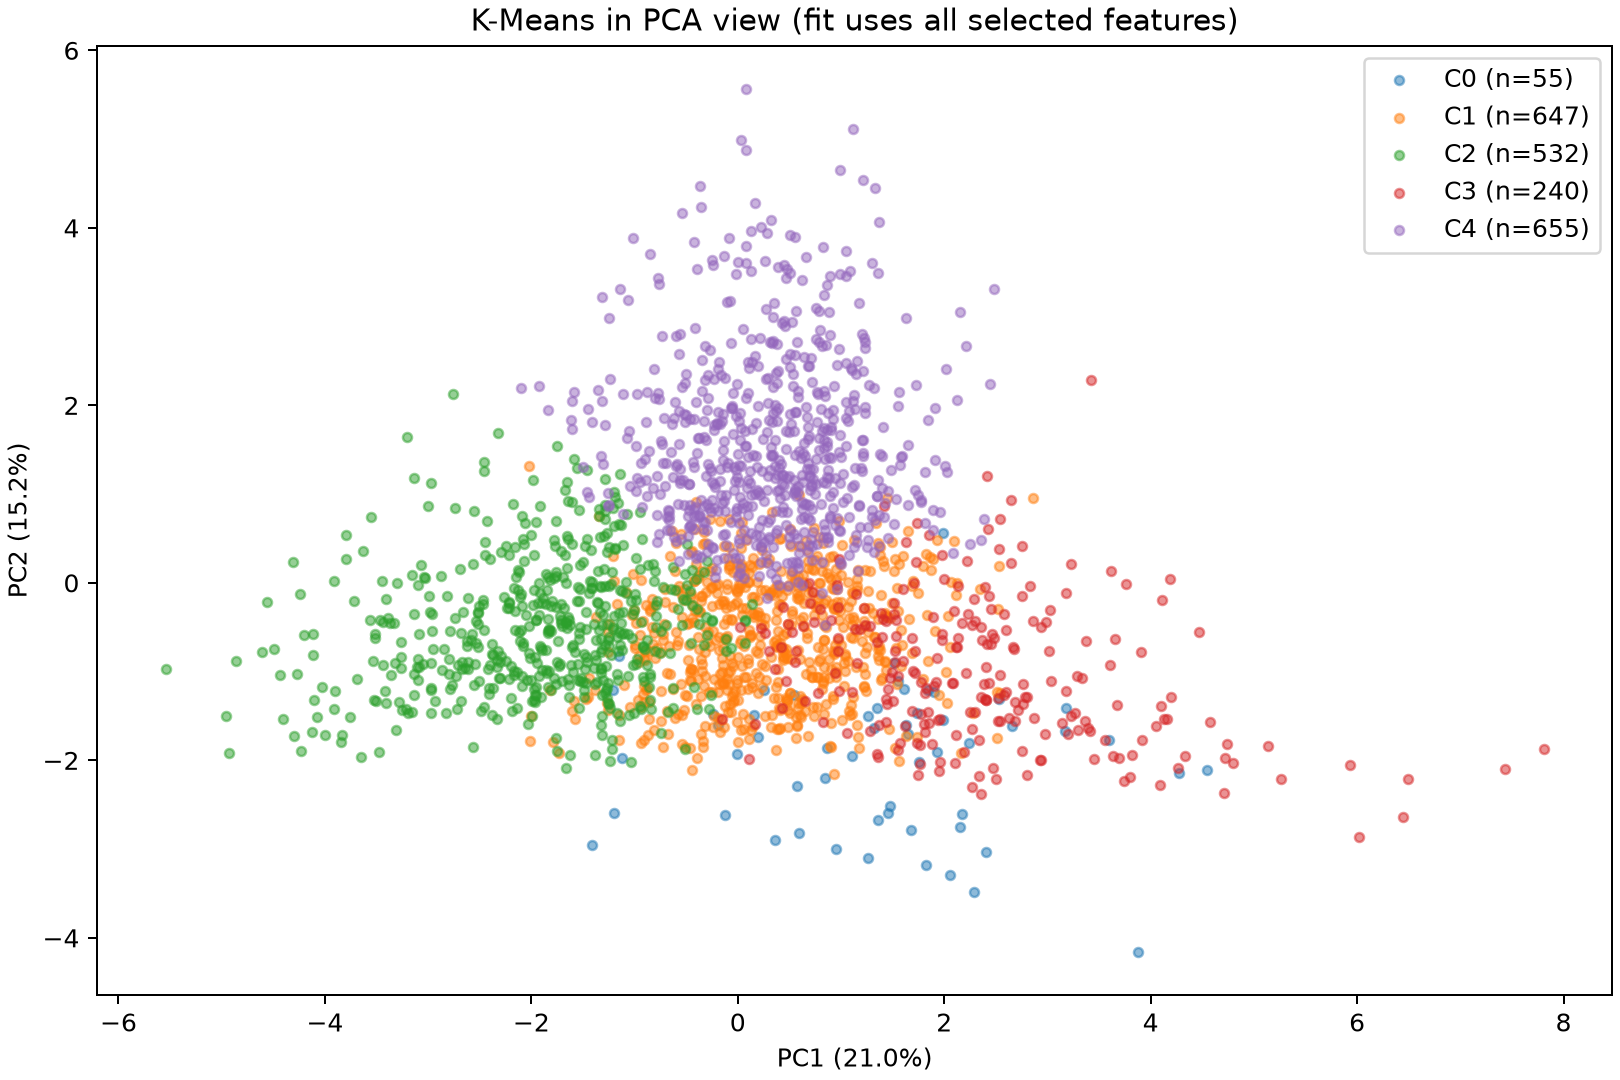

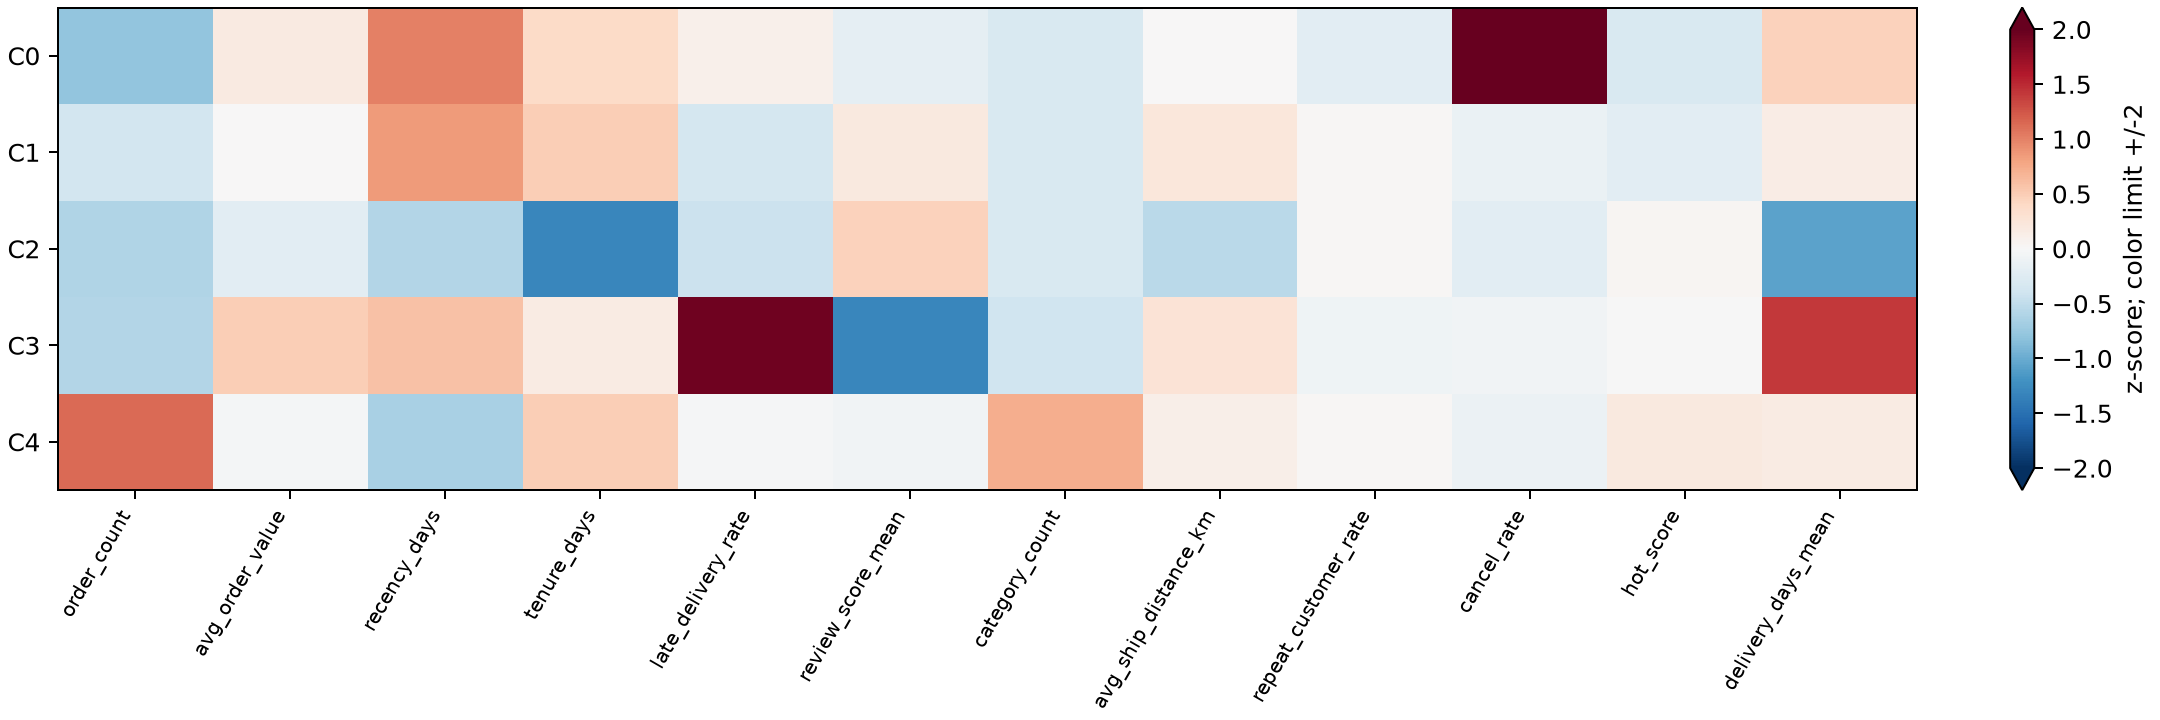

Variance PCA: [0.21012987444588002, 0.15157881972038834]
Hạn chế:
- Historical descriptive clustering, not out-of-sample validation
- Geography uses zip centroids, not actual shipping route
- Review and delivery shared by all sellers of an order
- Review answer timestamp records customer survey response, not seller response
- Cancellation denominator covers only orders with seller-attributable items


Bàn giao dimension: 3095 seller


In [5]:
display(summary)
display(Image(filename=str(OUTPUT/'pca_kmeans.png')))
display(Image(filename=str(OUTPUT/'cluster_centroids.png')))
print('Variance PCA:',details['pca_explained_variance_ratio'])
print('Hạn chế:',*details['limitations'],sep='\n- ')
dimension=pd.read_csv(OUTPUT/'seller_segment_dimension.csv')
assert dimension.seller_id.is_unique
print('Bàn giao dimension:',len(dimension),'seller')


## Phần leader tiếp tục
Chạy GMM và DBSCAN trên đúng ma trận v2; so ba mô hình, chọn mô hình cuối, đặt tên phân khúc dựa vào profile và chính sách kinh doanh. Dùng bảng mapping seller–segment–region cùng script SQL/SSAS để nối phân tích khai phá với OLAP. Chưa công bố K-Means là mô hình tốt nhất trong ba phương pháp.
